# FP16 Client-Update Compression in Federated SIPaKMeD Classification

**Model:** MobileNetV3-Small  
**Question:** Can clients transmit FP16 model updates instead of FP32 updates while retaining similar test Macro-F1 and per-class recall under non-IID data?

This notebook trains two paired federated runs for each seed:

1. **FP32 uplink:** local training and client-update transmission use FP32.
2. **FP16 uplink:** local training and server aggregation remain FP32, but each client serializes its model-update deltas as FP16; the server converts them back to FP32 before weighted aggregation.

The data split, client partition, starting weights, local minibatch order, augmentation randomness, rounds and local epochs are paired between the two modes for each seed. The server-to-client broadcast remains FP32. The notebook measures serialized PyTorch payload sizes in memory; it does **not** emulate a live network or include TCP/TLS/Flower overhead.

## Before running in Kaggle

1. Create a Kaggle Notebook and **Add Input**: `Cervical Cancer largest dataset (SipakMed)`.
2. Select a GPU accelerator (T4/P100 if available). Internet is only needed if pretrained torchvision weights are not already cached.
3. Run the **data audit** cell before the training cells. The canonical SIPaKMeD single-cell task contains 4,049 cropped cells. The original package may also contain 966 parent cluster images; this notebook filters for a `CROPPED` path and will stop if it cannot find one.
4. Keep `GROUP_ID_REGEX = None` for the first run unless you have verified the source-cluster ID pattern in the printed filenames. If you set it, use a regex with one capture group and enable grouped splitting.
5. Run all cells. CSVs, plots, checkpoints, and a presentation summary will be written under `/kaggle/working/fp16_fl_results/`.

> This is a simulated FL experiment on one Kaggle process. It does not provide a formal privacy guarantee. Use only de-identified/public data. FP16 update transmission reduces the update payload, not the deployed inference model size.

In [1]:
# Core Kaggle / Python libraries are normally preinstalled.
import os
import re
import io
import json
import time
import math
import random
import warnings
from pathlib import Path
from collections import Counter

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image

import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader, Subset
from torchvision import models, transforms
from sklearn.model_selection import train_test_split, StratifiedGroupKFold
from sklearn.metrics import (
    accuracy_score,
    f1_score,
    precision_score,
    recall_score,
    confusion_matrix,
)
from IPython.display import display

# -------------------------- Experiment configuration -------------------------
CLASS_NAMES = [
    "im_Dyskeratotic",
    "im_Koilocytotic",
    "im_Metaplastic",
    "im_Parabasal",
    "im_Superficial-Intermediate",
]
CLASS_TO_IDX = {name: i for i, name in enumerate(CLASS_NAMES)}

CROPPED_ONLY = True              # Do not silently mix parent cluster images.
USE_GROUPED_SPLIT = False        # Set True only after verifying group IDs below.
GROUP_ID_REGEX = None            # Regex applied to filename stem; capture group 1 = source group.

NUM_CLIENTS = 3
DIRICHLET_ALPHA = 0.5
NUM_ROUNDS = 10
LOCAL_EPOCHS = 2
BATCH_SIZE = 32
LEARNING_RATE = 2e-4
NUM_WORKERS = 0                  # Keeps paired augmentation randomness reproducible.
PRETRAINED = True
SPLIT_SEED = 42
SEEDS = [42, 123, 2026]           # Use [42] for a quick smoke run, then run all three.

IMAGE_SIZE = 224
OUTPUT_DIR = Path("/kaggle/working/fp16_fl_results")
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

# Kaggle's default input directory. If auto-discovery fails, set this directly,
# for example: Path('/kaggle/input/cervical-cancer-largest-dataset-sipakmed').
DATA_ROOT_OVERRIDE = None

print("Configuration:")
print({
    "clients": NUM_CLIENTS,
    "Dirichlet alpha": DIRICHLET_ALPHA,
    "rounds": NUM_ROUNDS,
    "local epochs": LOCAL_EPOCHS,
    "batch size": BATCH_SIZE,
    "learning rate": LEARNING_RATE,
    "seeds": SEEDS,
    "pretrained requested": PRETRAINED,
    "crop-only": CROPPED_ONLY,
    "grouped split": USE_GROUPED_SPLIT,
})

Configuration:
{'clients': 3, 'Dirichlet alpha': 0.5, 'rounds': 10, 'local epochs': 2, 'batch size': 32, 'learning rate': 0.0002, 'seeds': [42, 123, 2026], 'pretrained requested': True, 'crop-only': True, 'grouped split': False}


In [2]:
def set_seed(seed: int) -> None:
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("PyTorch:", torch.__version__)
print("Device:", DEVICE)
if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))
else:
    warnings.warn("GPU is not enabled. This experiment will be considerably slower on CPU.")

PyTorch: 2.11.0+cu128
Device: cuda
GPU: Tesla T4


## 1. Find the Kaggle dataset and audit its folders

This step is deliberately explicit: it prints how many images are inside `CROPPED` and outside it for each class. If the total is 5,015 but the cropped total is 4,049, the parent cluster images are being excluded from this cell-classification experiment.

In [3]:
IMAGE_EXTENSIONS = {".bmp", ".png", ".jpg", ".jpeg", ".tif", ".tiff"}


def find_dataset_root(input_root=Path("/kaggle/input")):
    if DATA_ROOT_OVERRIDE is not None:
        root = Path(DATA_ROOT_OVERRIDE)
        if all((root / name).is_dir() for name in CLASS_NAMES):
            return root
        raise FileNotFoundError(f"DATA_ROOT_OVERRIDE does not contain all five class folders: {root}")

    if not input_root.exists():
        raise FileNotFoundError("/kaggle/input was not found. Add the SIPaKMeD dataset as a Kaggle Input.")

    candidates = set()
    # The class directories are siblings at the correct root. Nested repeated
    # class folders are ignored unless all five class names are siblings there.
    for class_dir in input_root.rglob(CLASS_NAMES[0]):
        if class_dir.is_dir() and all((class_dir.parent / name).is_dir() for name in CLASS_NAMES):
            candidates.add(class_dir.parent.resolve())

    if not candidates:
        raise FileNotFoundError(
            "Could not auto-detect a root containing all five im_* class folders. "
            "Set DATA_ROOT_OVERRIDE in the configuration cell."
        )

    candidates = sorted(candidates, key=lambda p: str(p))
    print("Candidate dataset roots:")
    for candidate in candidates:
        print(" -", candidate)
    if len(candidates) != 1:
        raise RuntimeError(
            "More than one dataset root contains all five classes. Set DATA_ROOT_OVERRIDE "
            "explicitly in the configuration cell rather than choosing one silently."
        )
    return candidates[0]

DATA_ROOT = find_dataset_root()
print("Using DATA_ROOT:", DATA_ROOT)


def image_files(folder: Path):
    return sorted(
        p for p in folder.rglob("*")
        if p.is_file() and p.suffix.lower() in IMAGE_EXTENSIONS
    )


def is_cropped_path(path: Path) -> bool:
    return any(part.casefold() == "cropped" for part in path.parts)


audit_rows = []
manifest_paths = []
manifest_targets = []
for class_name in CLASS_NAMES:
    class_dir = DATA_ROOT / class_name
    all_paths = image_files(class_dir)
    crop_paths = [p for p in all_paths if is_cropped_path(p)]
    other_paths = [p for p in all_paths if not is_cropped_path(p)]
    audit_rows.append({
        "class": class_name,
        "all images under class folder": len(all_paths),
        "CROPPED single-cell images": len(crop_paths),
        "other images (often clusters)": len(other_paths),
    })
    selected = crop_paths if CROPPED_ONLY else all_paths
    manifest_paths.extend(selected)
    manifest_targets.extend([CLASS_TO_IDX[class_name]] * len(selected))

audit_df = pd.DataFrame(audit_rows)
display(audit_df)
print("All images:", int(audit_df["all images under class folder"].sum()))
print("Selected images for this experiment:", len(manifest_paths))

EXPECTED_CROPPED_COUNTS = {
    "im_Dyskeratotic": 813,
    "im_Koilocytotic": 825,
    "im_Metaplastic": 793,
    "im_Parabasal": 787,
    "im_Superficial-Intermediate": 831,
}
observed_crops = dict(zip(audit_df["class"], audit_df["CROPPED single-cell images"]))
if CROPPED_ONLY and not any(audit_df["CROPPED single-cell images"]):
    raise RuntimeError(
        "No CROPPED folders were found. Do not silently train on mixed parent-cluster images; "
        "inspect the Kaggle folder layout and update is_cropped_path()."
    )
if CROPPED_ONLY and observed_crops != EXPECTED_CROPPED_COUNTS:
    warnings.warn(
        "Cropped-image counts differ from the canonical SIPaKMeD counts. "
        "Check the dataset version and the printed folder audit before interpreting results."
    )

if USE_GROUPED_SPLIT and GROUP_ID_REGEX is None:
    raise ValueError("Set GROUP_ID_REGEX after inspecting filenames before enabling grouped splitting.")

print("\nExample selected filenames (inspect these before setting GROUP_ID_REGEX):")
for p in manifest_paths[:12]:
    print(p.name)

Candidate dataset roots:
 - /kaggle/input/datasets/prahladmehandiratta/cervical-cancer-largest-dataset-sipakmed
Using DATA_ROOT: /kaggle/input/datasets/prahladmehandiratta/cervical-cancer-largest-dataset-sipakmed


,class,all images under class folder,CROPPED single-cell images,other images (often clusters)
0,im_Dyskeratotic,1036,813,223
1,im_Koilocytotic,1063,825,238
2,im_Metaplastic,1064,793,271
3,im_Parabasal,895,787,108
4,im_Superficial-Intermediate,957,831,126


All images: 5015
Selected images for this experiment: 4049

Example selected filenames (inspect these before setting GROUP_ID_REGEX):
001_01.bmp
001_02.bmp
001_03.bmp
001_04.bmp
001_05.bmp
002_01.bmp
002_02.bmp
002_03.bmp
002_04.bmp
002_05.bmp
002_06.bmp
002_07.bmp


## 2. Create a fixed train/validation/test split

The 80/10/10 split is created once and reused by both communication modes. If the filename contains a verified source-cluster identifier, configure `GROUP_ID_REGEX` and enable `USE_GROUPED_SPLIT` to prevent cells from the same parent group crossing splits. Do not guess a regex: inspect the filenames printed above first.

In [4]:
from sklearn.model_selection import StratifiedGroupKFold

manifest_paths = [str(p) for p in manifest_paths]
y_all = np.asarray(manifest_targets, dtype=np.int64)


def extract_groups(paths, regex):
    groups = []
    for path in paths:
        match = re.search(regex, Path(path).stem)
        if match is None or match.lastindex is None:
            raise ValueError(
                f"GROUP_ID_REGEX did not produce capture group 1 for filename: {Path(path).name}"
            )
        groups.append(match.group(1))
    return np.asarray(groups)


all_indices = np.arange(len(y_all))
if USE_GROUPED_SPLIT:
    groups_all = extract_groups(manifest_paths, GROUP_ID_REGEX)
    outer = StratifiedGroupKFold(n_splits=10, shuffle=True, random_state=SPLIT_SEED)
    trainval_idx, test_idx = next(outer.split(np.zeros(len(y_all)), y_all, groups_all))
    inner = StratifiedGroupKFold(n_splits=9, shuffle=True, random_state=SPLIT_SEED + 1)
    train_rel, val_rel = next(
        inner.split(
            np.zeros(len(trainval_idx)),
            y_all[trainval_idx],
            groups_all[trainval_idx],
        )
    )
    train_idx = trainval_idx[train_rel]
    val_idx = trainval_idx[val_rel]
    assert set(groups_all[train_idx]).isdisjoint(set(groups_all[val_idx]))
    assert set(groups_all[train_idx]).isdisjoint(set(groups_all[test_idx]))
    assert set(groups_all[val_idx]).isdisjoint(set(groups_all[test_idx]))
    print("Split mode: grouped by verified source-cluster IDs")
else:
    groups_all = None
    trainval_idx, test_idx = train_test_split(
        all_indices,
        test_size=0.10,
        random_state=SPLIT_SEED,
        stratify=y_all,
    )
    train_idx, val_idx = train_test_split(
        trainval_idx,
        test_size=1/9,  # 10% of the whole set, leaving 80% for training.
        random_state=SPLIT_SEED + 1,
        stratify=y_all[trainval_idx],
    )
    print("Split mode: stratified image-level split")
    print("NOTE: image-level splitting is not source-cluster-disjoint.")

train_paths = [manifest_paths[i] for i in train_idx]
val_paths = [manifest_paths[i] for i in val_idx]
test_paths = [manifest_paths[i] for i in test_idx]
y_train = y_all[train_idx]
y_val = y_all[val_idx]
y_test = y_all[test_idx]


def class_counts(labels):
    return {name: int(np.sum(labels == i)) for i, name in enumerate(CLASS_NAMES)}

split_df = pd.DataFrame([
    {"split": "train", "n": len(y_train), **class_counts(y_train)},
    {"split": "validation", "n": len(y_val), **class_counts(y_val)},
    {"split": "test", "n": len(y_test), **class_counts(y_test)},
])
display(split_df)
print("Split sizes:", len(train_paths), len(val_paths), len(test_paths))

Split mode: stratified image-level split
NOTE: image-level splitting is not source-cluster-disjoint.


,split,n,im_Dyskeratotic,im_Koilocytotic,im_Metaplastic,im_Parabasal,im_Superficial-Intermediate
0,train,3239,651,659,635,629,665
1,validation,405,81,83,79,79,83
2,test,405,81,83,79,79,83


Split sizes: 3239 405 405


## 3. Build datasets and Dirichlet client partitions

The same train indices, client partitions, and random seed are reused for FP32 and FP16 within each paired run. The validation split is used for per-round curves; the test split is only evaluated after the final round.

In [5]:
class CellImageDataset(Dataset):
    def __init__(self, paths, labels, transform=None):
        self.paths = list(paths)
        self.labels = np.asarray(labels, dtype=np.int64)
        self.transform = transform

    def __len__(self):
        return len(self.paths)

    def __getitem__(self, index):
        path = self.paths[index]
        with Image.open(path) as image:
            image = image.convert("RGB")
        if self.transform is not None:
            image = self.transform(image)
        return image, int(self.labels[index])


TRAIN_TRANSFORM = transforms.Compose([
    transforms.Resize((IMAGE_SIZE, IMAGE_SIZE)),
    transforms.RandomHorizontalFlip(),
    transforms.RandomVerticalFlip(),
    transforms.RandomRotation(20),
    transforms.ToTensor(),
    transforms.Normalize([0.485, 0.456, 0.406], [0.229, 0.224, 0.225]),
])
EVAL_TRANSFORM = transforms.Compose([
    transforms.Resize((IMAGE_SIZE, IMAGE_SIZE)),
    transforms.ToTensor(),
    transforms.Normalize([0.485, 0.456, 0.406], [0.229, 0.224, 0.225]),
])

train_dataset = CellImageDataset(train_paths, y_train, TRAIN_TRANSFORM)
val_dataset = CellImageDataset(val_paths, y_val, EVAL_TRANSFORM)
test_dataset = CellImageDataset(test_paths, y_test, EVAL_TRANSFORM)
val_loader = DataLoader(val_dataset, batch_size=64, shuffle=False, num_workers=NUM_WORKERS)
test_loader = DataLoader(test_dataset, batch_size=64, shuffle=False, num_workers=NUM_WORKERS)


def create_dirichlet_partitions(labels, num_clients, alpha, seed, max_attempts=100):
    labels = np.asarray(labels)
    rng = np.random.default_rng(seed)
    for attempt in range(max_attempts):
        client_indices = [[] for _ in range(num_clients)]
        for class_id in np.unique(labels):
            class_indices = np.where(labels == class_id)[0]
            rng.shuffle(class_indices)
            proportions = rng.dirichlet(np.full(num_clients, alpha, dtype=np.float64))
            boundaries = np.floor(np.cumsum(proportions)[:-1] * len(class_indices)).astype(int)
            pieces = np.split(class_indices, boundaries)
            for client_id, piece in enumerate(pieces):
                client_indices[client_id].extend(piece.tolist())
        client_indices = [np.asarray(sorted(x), dtype=np.int64) for x in client_indices]
        if all(len(x) > 0 for x in client_indices):
            merged = np.concatenate(client_indices)
            if len(merged) == len(labels) and len(np.unique(merged)) == len(labels):
                return client_indices
    raise RuntimeError("Could not generate non-empty Dirichlet client partitions after many attempts.")


def show_client_distribution(partitions, labels):
    rows = []
    for client_id, idxs in enumerate(partitions):
        rows.append({"client": client_id, "n": len(idxs), **class_counts(labels[idxs])})
    return pd.DataFrame(rows)

client_partitions_by_seed = {}
for seed in SEEDS:
    parts = create_dirichlet_partitions(
        y_train, NUM_CLIENTS, DIRICHLET_ALPHA, seed=seed + 10_000
    )
    client_partitions_by_seed[seed] = parts
    print(f"\nClient class counts for seed {seed}:")
    display(show_client_distribution(parts, y_train))


Client class counts for seed 42:


,client,n,im_Dyskeratotic,im_Koilocytotic,im_Metaplastic,im_Parabasal,im_Superficial-Intermediate
0,0,44,25,4,14,0,1
1,1,2782,553,560,534,619,516
2,2,413,73,95,87,10,148



Client class counts for seed 123:


,client,n,im_Dyskeratotic,im_Koilocytotic,im_Metaplastic,im_Parabasal,im_Superficial-Intermediate
0,0,1255,305,183,0,225,542
1,1,813,318,380,50,58,7
2,2,1171,28,96,585,346,116



Client class counts for seed 2026:


,client,n,im_Dyskeratotic,im_Koilocytotic,im_Metaplastic,im_Parabasal,im_Superficial-Intermediate
0,0,1239,23,616,539,23,38
1,1,936,610,5,84,2,235
2,2,1064,18,38,12,604,392


## 4. Initialize MobileNetV3-Small once per seed

For each seed, the FP32 and FP16 arms receive exactly the same starting state. If Kaggle cannot download the ImageNet weights, the cell falls back to random initialization and prints a warning; keep that fact in your final report.

In [6]:
def build_model(weights=None):
    model = models.mobilenet_v3_small(weights=weights)
    model.classifier[3] = nn.Linear(model.classifier[3].in_features, len(CLASS_NAMES))
    return model


def clone_state(state):
    return {key: value.detach().cpu().clone() for key, value in state.items()}


def make_initial_state(seed):
    set_seed(seed)
    pretrained_loaded = False
    if PRETRAINED:
        try:
            weights = models.MobileNet_V3_Small_Weights.DEFAULT
            model = build_model(weights=weights)
            pretrained_loaded = True
        except Exception as exc:
            warnings.warn(
                f"Could not load ImageNet weights ({exc}). Using random initialization for this seed."
            )
            set_seed(seed)
            model = build_model(weights=None)
    else:
        model = build_model(weights=None)
    return clone_state(model.state_dict()), pretrained_loaded


initial_states_by_seed = {}
pretrained_status = {}
for seed in SEEDS:
    initial_states_by_seed[seed], pretrained_status[seed] = make_initial_state(seed)
print("ImageNet pretrained weights loaded by seed:", pretrained_status)
print("Class-index order:", CLASS_NAMES)

Downloading: "https://download.pytorch.org/models/mobilenet_v3_small-047dcff4.pth" to /root/.cache/torch/hub/checkpoints/mobilenet_v3_small-047dcff4.pth


100%|██████████| 9.83M/9.83M [00:00<00:00, 101MB/s]


ImageNet pretrained weights loaded by seed: {42: True, 123: True, 2026: True}
Class-index order: ['im_Dyskeratotic', 'im_Koilocytotic', 'im_Metaplastic', 'im_Parabasal', 'im_Superficial-Intermediate']


## 5. Local training, evaluation, and serialized communication accounting

All local training is FP32 in both arms. The FP16 arm casts only the **client-to-server update delta** to FP16 for serialization. The server dequantizes it to FP32 before weighted aggregation. Server-to-client global-model broadcasts remain FP32 in both arms.

The notebook records (a) raw tensor-payload bytes and (b) actual in-memory PyTorch-serialized payload bytes. The latter includes serialization metadata but excludes transport protocol, TLS, and real network overhead.

In [7]:
def make_client_loaders(seed, client_partitions):
    loaders = []
    for client_id, indices in enumerate(client_partitions):
        generator = torch.Generator()
        generator.manual_seed(seed + 50_000 + client_id)
        subset = Subset(train_dataset, indices.tolist())
        loader = DataLoader(
            subset,
            batch_size=BATCH_SIZE,
            shuffle=True,
            num_workers=NUM_WORKERS,
            pin_memory=(DEVICE.type == "cuda"),
            generator=generator,
        )
        loaders.append(loader)
    return loaders


def serialize_size(payload):
    buffer = io.BytesIO()
    torch.save(payload, buffer)
    return len(buffer.getvalue())


def tensor_payload_size(payload):
    return sum(t.numel() * t.element_size() for t in payload.values())


def train_one_client(model, loader, epochs):
    model.train()
    optimizer = torch.optim.Adam(model.parameters(), lr=LEARNING_RATE)
    criterion = nn.CrossEntropyLoss()
    loss_sum = 0.0
    batches = 0
    for _ in range(epochs):
        for images, labels in loader:
            images = images.to(DEVICE, non_blocking=True)
            labels = labels.to(DEVICE, non_blocking=True)
            optimizer.zero_grad(set_to_none=True)
            logits = model(images)
            loss = criterion(logits, labels)
            loss.backward()
            optimizer.step()
            loss_sum += float(loss.detach().item())
            batches += 1
    return clone_state(model.state_dict()), loss_sum / max(batches, 1)


def encode_updates_and_aggregate(global_state, local_states, client_sizes, mode):
    if mode not in {"FP32 uplink", "FP16 uplink"}:
        raise ValueError(f"Unknown communication mode: {mode}")

    total = float(sum(client_sizes))
    weights = [n / total for n in client_sizes]
    wire_payloads = []
    upload_serialized_bytes = 0
    upload_tensor_bytes = 0

    wire_dtype = torch.float16 if mode == "FP16 uplink" else torch.float32
    for local_state in local_states:
        payload = {}
        for key, global_tensor in global_state.items():
            local_tensor = local_state[key]
            if global_tensor.is_floating_point():
                delta = local_tensor.float() - global_tensor.float()
                if not torch.isfinite(delta).all():
                    raise FloatingPointError(f"Non-finite update in tensor {key}")
                payload[key] = delta.to(wire_dtype).cpu()
            else:
                # Integer buffers such as num_batches_tracked are not quantized.
                payload[key] = local_tensor.cpu().clone()
        wire_payloads.append(payload)
        upload_serialized_bytes += serialize_size(payload)
        upload_tensor_bytes += tensor_payload_size(payload)

    new_global_state = {}
    for key, global_tensor in global_state.items():
        if global_tensor.is_floating_point():
            aggregated_delta = torch.zeros_like(global_tensor, dtype=torch.float32)
            for weight, payload in zip(weights, wire_payloads):
                aggregated_delta.add_(payload[key].float(), alpha=float(weight))
            new_global_state[key] = (global_tensor.float() + aggregated_delta).to(global_tensor.dtype)
        else:
            # Integer buffers cannot be meaningfully averaged; keep the maximum
            # client counter, identically for both communication modes.
            stacked = torch.stack([payload[key].to(global_tensor.dtype) for payload in wire_payloads])
            new_global_state[key] = stacked.max(dim=0).values

    return new_global_state, upload_serialized_bytes, upload_tensor_bytes


def evaluate_state(state, loader, eval_model):
    eval_model.load_state_dict(state, strict=True)
    eval_model.eval()
    y_true, y_pred = [], []
    with torch.inference_mode():
        for images, labels in loader:
            logits = eval_model(images.to(DEVICE, non_blocking=True))
            predictions = logits.argmax(dim=1).cpu().numpy()
            y_pred.extend(predictions.tolist())
            y_true.extend(labels.numpy().tolist())
    labels_range = list(range(len(CLASS_NAMES)))
    metrics = {
        "accuracy": accuracy_score(y_true, y_pred),
        "macro_f1": f1_score(y_true, y_pred, labels=labels_range, average="macro", zero_division=0),
        "macro_precision": precision_score(y_true, y_pred, labels=labels_range, average="macro", zero_division=0),
        "macro_recall": recall_score(y_true, y_pred, labels=labels_range, average="macro", zero_division=0),
        "per_class_recall": recall_score(y_true, y_pred, labels=labels_range, average=None, zero_division=0),
        "confusion_matrix": confusion_matrix(y_true, y_pred, labels=labels_range),
    }
    return metrics, np.asarray(y_true), np.asarray(y_pred)


def sync_device():
    if DEVICE.type == "cuda":
        torch.cuda.synchronize()

## 6. Run paired FP32-vs-FP16 federated experiments

A seed defines a client partition and a starting classifier head. Within that seed, the exact same initialization, client data, minibatch shuffle seeds, and augmentation RNG are reset for the two communication modes. Validation Macro-F1 is recorded after each round. The held-out test split is used only once at the end of each run.

In [8]:
def run_federated(mode, seed, initial_state, client_partitions):
    set_seed(seed + 70_000)  # Reset randomness so paired FP32/FP16 runs match.
    client_loaders = make_client_loaders(seed + 70_000, client_partitions)
    client_sizes = [len(indices) for indices in client_partitions]

    global_state = clone_state(initial_state)
    local_model = build_model(weights=None).to(DEVICE)
    eval_model = build_model(weights=None).to(DEVICE)
    history = []
    total_train_seconds = 0.0

    for round_index in range(1, NUM_ROUNDS + 1):
        # Each client receives the full FP32 global state in both arms.
        downlink_one_client = serialize_size(global_state)
        downlink_serialized_bytes = NUM_CLIENTS * downlink_one_client

        local_states, client_losses = [], []
        sync_device()
        round_start = time.perf_counter()
        for client_id, loader in enumerate(client_loaders):
            local_model.load_state_dict(global_state, strict=True)
            local_state, local_loss = train_one_client(local_model, loader, LOCAL_EPOCHS)
            local_states.append(local_state)
            client_losses.append(local_loss)
        sync_device()
        train_seconds = time.perf_counter() - round_start
        total_train_seconds += train_seconds

        global_state, upload_serialized_bytes, upload_tensor_bytes = encode_updates_and_aggregate(
            global_state, local_states, client_sizes, mode
        )
        val_metrics, _, _ = evaluate_state(global_state, val_loader, eval_model)
        weighted_train_loss = float(np.average(client_losses, weights=client_sizes))

        history.append({
            "seed": seed,
            "mode": mode,
            "round": round_index,
            "weighted_local_train_loss": weighted_train_loss,
            "val_accuracy": val_metrics["accuracy"],
            "val_macro_f1": val_metrics["macro_f1"],
            "upload_serialized_bytes": upload_serialized_bytes,
            "upload_tensor_bytes": upload_tensor_bytes,
            "downlink_serialized_bytes": downlink_serialized_bytes,
            "total_two_way_serialized_bytes": upload_serialized_bytes + downlink_serialized_bytes,
            "round_local_train_seconds": train_seconds,
        })
        print(
            f"seed={seed} | {mode:10s} | round={round_index:02d}/{NUM_ROUNDS} "
            f"| val Macro-F1={val_metrics['macro_f1']:.4f} "
            f"| uplink={upload_serialized_bytes / 1e6:.3f} MB"
        )

    test_metrics, y_true, y_pred = evaluate_state(global_state, test_loader, eval_model)
    result = {
        "seed": seed,
        "mode": mode,
        "test_accuracy": test_metrics["accuracy"],
        "test_macro_f1": test_metrics["macro_f1"],
        "test_macro_precision": test_metrics["macro_precision"],
        "test_macro_recall": test_metrics["macro_recall"],
        "per_class_recall": test_metrics["per_class_recall"].tolist(),
        "confusion_matrix": test_metrics["confusion_matrix"].tolist(),
        "total_local_train_seconds": total_train_seconds,
    }

    checkpoint_path = OUTPUT_DIR / f"global_{mode.replace(' ', '_')}_seed_{seed}.pth"
    torch.save(global_state, checkpoint_path)
    result["checkpoint"] = str(checkpoint_path)
    return result, history


final_rows = []
history_rows = []
confusion_matrices = {}

for seed in SEEDS:
    print(f"\n===== Paired experiment seed {seed} =====")
    initial_state = initial_states_by_seed[seed]
    client_partitions = client_partitions_by_seed[seed]

    for mode in ["FP32 uplink", "FP16 uplink"]:
        print(f"\nStarting {mode}")
        result, history = run_federated(mode, seed, initial_state, client_partitions)
        final_rows.append(result)
        history_rows.extend(history)
        confusion_matrices[(seed, mode)] = np.asarray(result["confusion_matrix"])
        print(
            f"Final test: accuracy={result['test_accuracy']:.4f}, "
            f"Macro-F1={result['test_macro_f1']:.4f}, "
            f"Macro-recall={result['test_macro_recall']:.4f}"
        )

final_df = pd.DataFrame(final_rows)
history_df = pd.DataFrame(history_rows)
display(final_df.drop(columns=["per_class_recall", "confusion_matrix"]))


===== Paired experiment seed 42 =====

Starting FP32 uplink
seed=42 | FP32 uplink | round=01/10 | val Macro-F1=0.8901 | uplink=18.638 MB
seed=42 | FP32 uplink | round=02/10 | val Macro-F1=0.9581 | uplink=18.638 MB
seed=42 | FP32 uplink | round=03/10 | val Macro-F1=0.9704 | uplink=18.638 MB
seed=42 | FP32 uplink | round=04/10 | val Macro-F1=0.9728 | uplink=18.638 MB
seed=42 | FP32 uplink | round=05/10 | val Macro-F1=0.9779 | uplink=18.638 MB
seed=42 | FP32 uplink | round=06/10 | val Macro-F1=0.9582 | uplink=18.638 MB
seed=42 | FP32 uplink | round=07/10 | val Macro-F1=0.9657 | uplink=18.638 MB
seed=42 | FP32 uplink | round=08/10 | val Macro-F1=0.9803 | uplink=18.638 MB
seed=42 | FP32 uplink | round=09/10 | val Macro-F1=0.9633 | uplink=18.638 MB
seed=42 | FP32 uplink | round=10/10 | val Macro-F1=0.9853 | uplink=18.638 MB
Final test: accuracy=0.9802, Macro-F1=0.9804, Macro-recall=0.9804

Starting FP16 uplink
seed=42 | FP16 uplink | round=01/10 | val Macro-F1=0.8901 | uplink=9.423 MB
seed=

,seed,mode,test_accuracy,test_macro_f1,test_macro_precision,test_macro_recall,total_local_train_seconds,checkpoint
0,42,FP32 uplink,0.980247,0.980360,0.980570,0.980360,751.675568,/kaggle/working/fp16_fl_results/global_FP32_up...
1,42,FP16 uplink,0.967901,0.968145,0.968626,0.968130,279.032604,/kaggle/working/fp16_fl_results/global_FP16_up...
2,123,FP32 uplink,0.955556,0.955823,0.960723,0.954987,284.420478,/kaggle/working/fp16_fl_results/global_FP32_up...
3,123,FP16 uplink,0.955556,0.955953,0.960689,0.955049,284.984024,/kaggle/working/fp16_fl_results/global_FP16_up...
4,2026,FP32 uplink,0.948148,0.947792,0.949867,0.948669,291.607671,/kaggle/working/fp16_fl_results/global_FP32_up...
5,2026,FP16 uplink,0.953086,0.952770,0.954231,0.953610,289.163729,/kaggle/working/fp16_fl_results/global_FP16_up...


## 7. Presentation tables: accuracy, Macro-F1, class recall, and bytes

Report the **paired FP16-minus-FP32 Macro-F1 difference in percentage points** and the **measured serialized uplink savings**. Because the downlink stays FP32, total two-way savings will be lower than uplink savings. Do not describe this as a smaller inference model.

In [9]:
# Total communication per seed and mode. Bytes are serialized with torch.save;
# they are payload estimates, not packet-level network captures.
communication_df = (
    history_df.groupby(["seed", "mode"], as_index=False)
    .agg(
        uplink_serialized_bytes=("upload_serialized_bytes", "sum"),
        uplink_tensor_bytes=("upload_tensor_bytes", "sum"),
        downlink_serialized_bytes=("downlink_serialized_bytes", "sum"),
        total_two_way_serialized_bytes=("total_two_way_serialized_bytes", "sum"),
        local_training_seconds=("round_local_train_seconds", "sum"),
    )
)

display(communication_df.assign(
    uplink_MB=communication_df["uplink_serialized_bytes"] / 1e6,
    total_two_way_MB=communication_df["total_two_way_serialized_bytes"] / 1e6,
).drop(columns=["uplink_serialized_bytes", "uplink_tensor_bytes", "downlink_serialized_bytes", "total_two_way_serialized_bytes"]))

paired = final_df.merge(communication_df, on=["seed", "mode"], how="left")
wide_f1 = final_df.pivot(index="seed", columns="mode", values="test_macro_f1")
wide_acc = final_df.pivot(index="seed", columns="mode", values="test_accuracy")
wide_comm = communication_df.pivot(index="seed", columns="mode", values="uplink_serialized_bytes")
wide_total = communication_df.pivot(index="seed", columns="mode", values="total_two_way_serialized_bytes")

paired_summary = pd.DataFrame(index=wide_f1.index)
paired_summary["FP32 test Macro-F1"] = wide_f1["FP32 uplink"]
paired_summary["FP16 test Macro-F1"] = wide_f1["FP16 uplink"]
paired_summary["FP16-FP32 Macro-F1 (pp)"] = 100 * (wide_f1["FP16 uplink"] - wide_f1["FP32 uplink"])
paired_summary["FP32 uplink MB"] = wide_comm["FP32 uplink"] / 1e6
paired_summary["FP16 uplink MB"] = wide_comm["FP16 uplink"] / 1e6
paired_summary["Uplink savings (%)"] = 100 * (1 - wide_comm["FP16 uplink"] / wide_comm["FP32 uplink"])
paired_summary["Total two-way savings (%)"] = 100 * (1 - wide_total["FP16 uplink"] / wide_total["FP32 uplink"])
display(paired_summary.round(4))

print("\nMean ± SD across paired seeds:")
for column in paired_summary.columns:
    values = paired_summary[column].to_numpy(dtype=float)
    sd = values.std(ddof=1) if len(values) > 1 else 0.0
    print(f"{column}: {values.mean():.4f} ± {sd:.4f}")

,seed,mode,local_training_seconds,uplink_MB,total_two_way_MB
0,42,FP16 uplink,279.032604,94.23429,280.61322
1,42,FP32 uplink,751.675568,186.37893,372.75786
2,123,FP16 uplink,284.984024,94.23429,280.61322
3,123,FP32 uplink,284.420478,186.37893,372.75786
4,2026,FP16 uplink,289.163729,94.23429,280.61322
5,2026,FP32 uplink,291.607671,186.37893,372.75786


,FP32 test Macro-F1,FP16 test Macro-F1,FP16-FP32 Macro-F1 (pp),FP32 uplink MB,FP16 uplink MB,Uplink savings (%),Total two-way savings (%)
seed,,,,,,,
42,0.9804,0.9681,-1.2216,186.3789,94.2343,49.4394,24.7197
123,0.9558,0.9560,0.0130,186.3789,94.2343,49.4394,24.7197
2026,0.9478,0.9528,0.4978,186.3789,94.2343,49.4394,24.7197



Mean ± SD across paired seeds:
FP32 test Macro-F1: 0.9613 ± 0.0170
FP16 test Macro-F1: 0.9590 ± 0.0081
FP16-FP32 Macro-F1 (pp): -0.2369 ± 0.8865
FP32 uplink MB: 186.3789 ± 0.0000
FP16 uplink MB: 94.2343 ± 0.0000
Uplink savings (%): 49.4394 ± 0.0000
Total two-way savings (%): 24.7197 ± 0.0000


In [10]:
# Per-class recall, averaged across paired seeds.
per_class_rows = []
for row in final_rows:
    for class_index, recall in enumerate(row["per_class_recall"]):
        per_class_rows.append({
            "seed": row["seed"],
            "mode": row["mode"],
            "class": CLASS_NAMES[class_index],
            "recall": recall,
        })
per_class_df = pd.DataFrame(per_class_rows)
per_class_summary = (
    per_class_df.groupby(["mode", "class"])["recall"]
    .agg(mean="mean", std="std")
    .reset_index()
)
display(per_class_summary)

,mode,class,mean,std
0,FP16 uplink,im_Dyskeratotic,0.954733,0.025700
1,FP16 uplink,im_Koilocytotic,0.915663,0.067081
2,FP16 uplink,im_Metaplastic,0.936709,0.055176
3,FP16 uplink,im_Parabasal,0.991561,0.007308
4,FP16 uplink,im_Superficial-Intermediate,0.995984,0.006956
5,FP32 uplink,im_Dyskeratotic,0.962963,0.021383
6,FP32 uplink,im_Koilocytotic,0.919679,0.077459
7,FP32 uplink,im_Metaplastic,0.936709,0.066981
8,FP32 uplink,im_Parabasal,0.987342,0.012658
9,FP32 uplink,im_Superficial-Intermediate,1.000000,0.000000


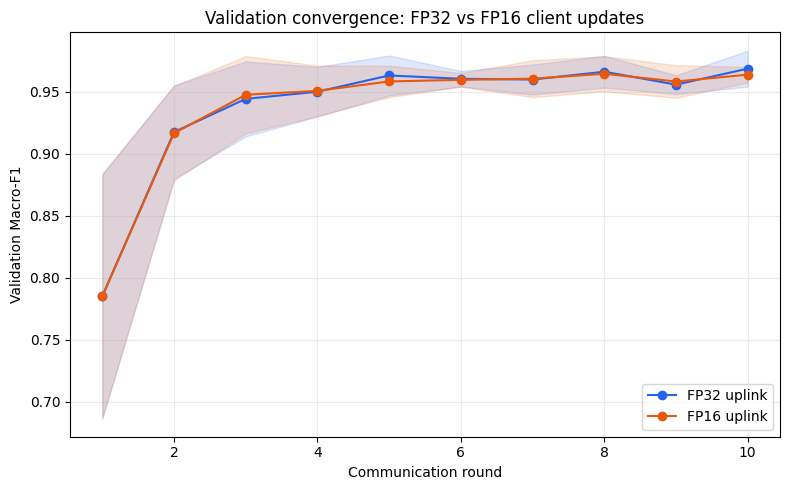

KeyError: False

<Figure size 600x500 with 0 Axes>

In [11]:
# Validation Macro-F1 by round (mean ± SD over seeds).
plt.figure(figsize=(8, 5))
for mode, color in [("FP32 uplink", "#2563eb"), ("FP16 uplink", "#ea580c")]:
    subset = history_df[history_df["mode"] == mode]
    grouped = subset.groupby("round")["val_macro_f1"].agg(["mean", "std"]).reset_index()
    std = grouped["std"].fillna(0)
    plt.plot(grouped["round"], grouped["mean"], marker="o", label=mode, color=color)
    plt.fill_between(grouped["round"], grouped["mean"] - std, grouped["mean"] + std, alpha=0.15, color=color)
plt.xlabel("Communication round")
plt.ylabel("Validation Macro-F1")
plt.title("Validation convergence: FP32 vs FP16 client updates")
plt.grid(alpha=0.25)
plt.legend()
plt.tight_layout()
plt.savefig(OUTPUT_DIR / "validation_macro_f1_by_round.png", dpi=180)
plt.show()

# Final test Macro-F1 across seeds.
plt.figure(figsize=(6, 5))
mode_order = ["FP32 uplink", "FP16 uplink"]
means = [final_df.loc[final_df.mode == mode, "test_macro_f1"].mean() for mode in mode_order]
stds = [final_df.loc[final_df.mode == mode, "test_macro_f1"].std(ddof=1) if len(SEEDS) > 1 else 0 for mode in mode_order]
plt.bar(mode_order, means, yerr=stds, capsize=6, color=["#2563eb", "#ea580c"])
plt.ylabel("Test Macro-F1")
plt.title("Final test Macro-F1 (mean ± SD across seeds)")
plt.ylim(0, 1)
plt.grid(axis="y", alpha=0.25)
plt.tight_layout()
plt.savefig(OUTPUT_DIR / "test_macro_f1_fp32_vs_fp16.png", dpi=180)
plt.show()

# Communication sizes per seed: uplink and two-way total.
comm_means = communication_df.groupby("mode")[["uplink_serialized_bytes", "total_two_way_serialized_bytes"]].mean() / 1e6
comm_stds = communication_df.groupby("mode")[["uplink_serialized_bytes", "total_two_way_serialized_bytes"]].std(ddof=1).fillna(0) / 1e6
ax = comm_means.loc[mode_order].plot(kind="bar", yerr=comm_stds.loc[mode_order], capsize=5, figsize=(8, 5), color=["#2563eb", "#ea580c"])
ax.set_ylabel("Serialized communication (MB per full run)")
ax.set_title("FP16 reduces uplink payload; downlink remains FP32")
ax.set_xticklabels(mode_order, rotation=0)
ax.grid(axis="y", alpha=0.25)
plt.tight_layout()
plt.savefig(OUTPUT_DIR / "communication_bytes_fp32_vs_fp16.png", dpi=180)
plt.show()

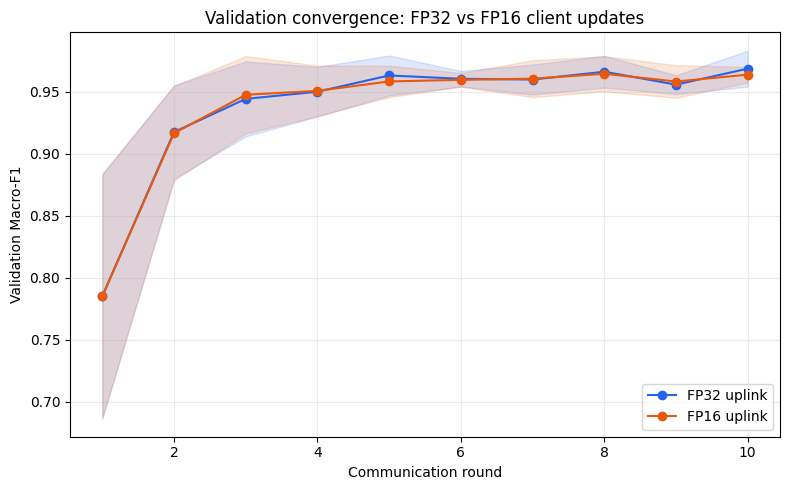

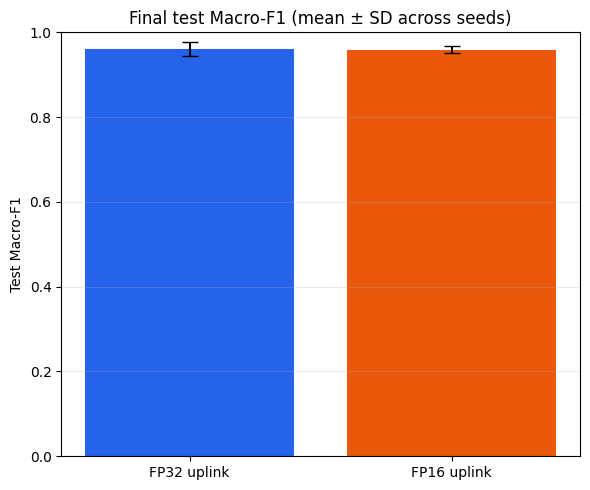

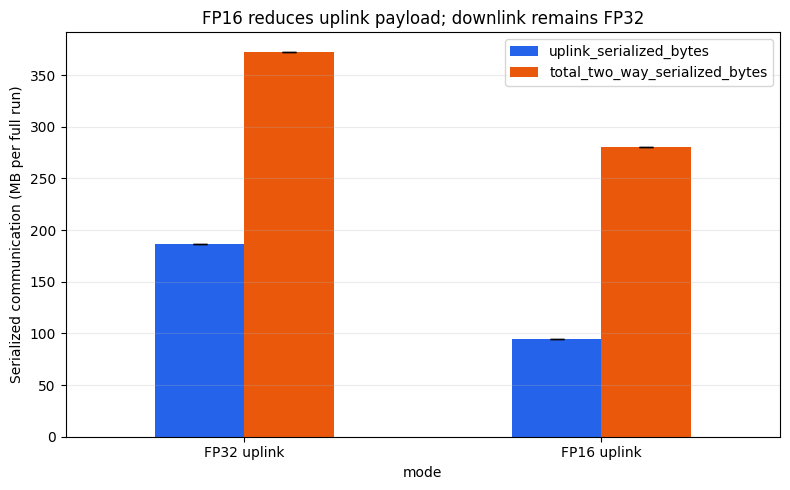

In [20]:

# Validation Macro-F1 by round (mean ± SD over seeds).
plt.figure(figsize=(8, 5))

for mode, color in [("FP32 uplink", "#2563eb"), ("FP16 uplink", "#ea580c")]:
    subset = history_df[history_df["mode"] == mode]
    grouped = subset.groupby("round")["val_macro_f1"].agg(["mean", "std"]).reset_index()
    std = grouped["std"].fillna(0)

    plt.plot(grouped["round"], grouped["mean"], marker="o", label=mode, color=color)
    plt.fill_between(
        grouped["round"],
        grouped["mean"] - std,
        grouped["mean"] + std,
        alpha=0.15,
        color=color
    )

plt.xlabel("Communication round")
plt.ylabel("Validation Macro-F1")
plt.title("Validation convergence: FP32 vs FP16 client updates")
plt.grid(alpha=0.25)
plt.legend()
plt.tight_layout()
plt.savefig(OUTPUT_DIR / "validation_macro_f1_by_round.png", dpi=180)
plt.show()


# Final test Macro-F1 across seeds.
plt.figure(figsize=(6, 5))

mode_order = ["FP32 uplink", "FP16 uplink"]

# FIX: Use final_df["mode"], not final_df.mode
means = [
    final_df.loc[final_df["mode"] == mode, "test_macro_f1"].mean()
    for mode in mode_order
]

stds = [
    final_df.loc[final_df["mode"] == mode, "test_macro_f1"].std(ddof=1)
    if len(SEEDS) > 1 else 0
    for mode in mode_order
]

plt.bar(
    mode_order,
    means,
    yerr=stds,
    capsize=6,
    color=["#2563eb", "#ea580c"]
)

plt.ylabel("Test Macro-F1")
plt.title("Final test Macro-F1 (mean ± SD across seeds)")
plt.ylim(0, 1)
plt.grid(axis="y", alpha=0.25)
plt.tight_layout()
plt.savefig(OUTPUT_DIR / "test_macro_f1_fp32_vs_fp16.png", dpi=180)
plt.show()


# Communication sizes per seed: uplink and two-way total.
comm_means = (
    communication_df.groupby("mode")[
        ["uplink_serialized_bytes", "total_two_way_serialized_bytes"]
    ].mean() / 1e6
)

comm_stds = (
    communication_df.groupby("mode")[
        ["uplink_serialized_bytes", "total_two_way_serialized_bytes"]
    ].std(ddof=1).fillna(0) / 1e6
)

ax = comm_means.loc[mode_order].plot(
    kind="bar",
    yerr=comm_stds.loc[mode_order],
    capsize=5,
    figsize=(8, 5),
    color=["#2563eb", "#ea580c"]
)

ax.set_ylabel("Serialized communication (MB per full run)")
ax.set_title("FP16 reduces uplink payload; downlink remains FP32")
ax.set_xticklabels(mode_order, rotation=0)
ax.grid(axis="y", alpha=0.25)

plt.tight_layout()
plt.savefig(OUTPUT_DIR / "communication_bytes_fp32_vs_fp16.png", dpi=180)
plt.show()


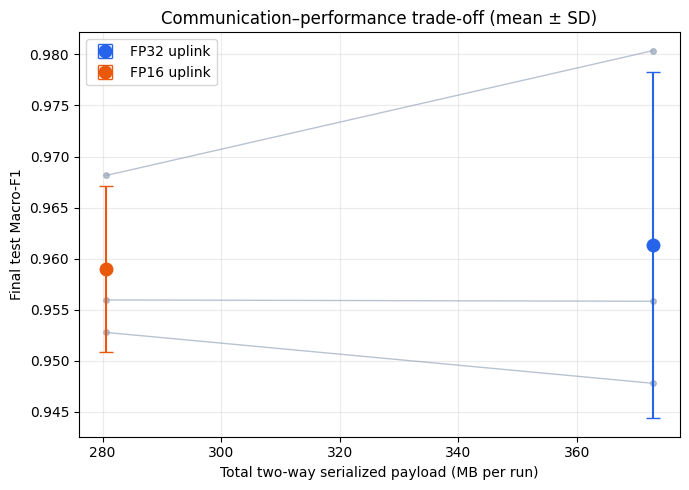

In [12]:
# Direct communication-performance trade-off using total two-way payload bytes.
tradeoff_df = final_df.merge(communication_df, on=["seed", "mode"], how="left")
fig, ax = plt.subplots(figsize=(7, 5))
for seed in sorted(SEEDS):
    paired_seed = tradeoff_df[tradeoff_df["seed"] == seed].set_index("mode").loc[mode_order]
    ax.plot(
        paired_seed["total_two_way_serialized_bytes"] / 1e6,
        paired_seed["test_macro_f1"],
        color="#94a3b8", alpha=0.65, linewidth=1, marker="o", markersize=4,
    )
for mode, color in [("FP32 uplink", "#2563eb"), ("FP16 uplink", "#ea580c")]:
    subset = tradeoff_df[tradeoff_df["mode"] == mode]
    x = subset["total_two_way_serialized_bytes"] / 1e6
    y = subset["test_macro_f1"]
    ax.errorbar(
        x.mean(), y.mean(),
        xerr=(x.std(ddof=1) if len(x) > 1 else 0),
        yerr=(y.std(ddof=1) if len(y) > 1 else 0),
        fmt="o", color=color, ecolor=color, capsize=5, markersize=9, label=mode,
    )
ax.set_xlabel("Total two-way serialized payload (MB per run)")
ax.set_ylabel("Final test Macro-F1")
ax.set_title("Communication–performance trade-off (mean ± SD)")
ax.grid(alpha=0.25)
ax.legend()
plt.tight_layout()
plt.savefig(OUTPUT_DIR / "macro_f1_vs_two_way_bytes.png", dpi=180)
plt.show()

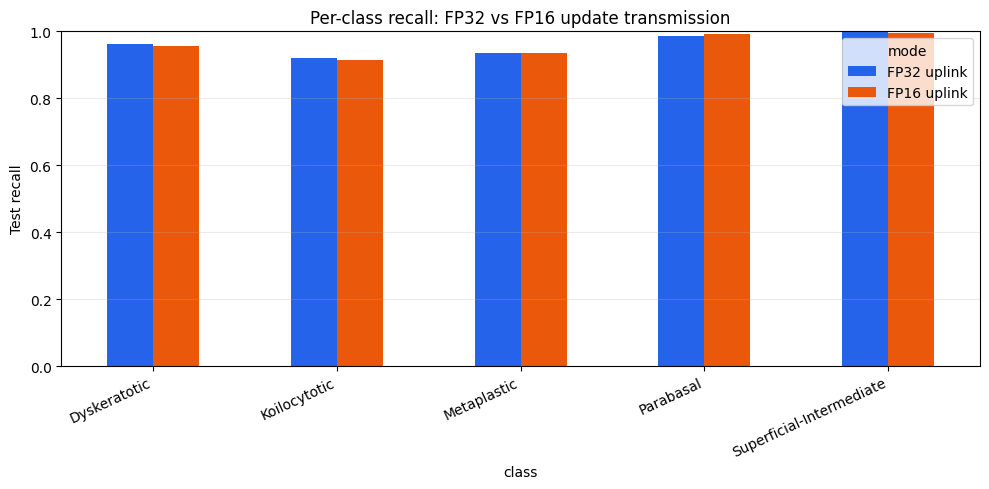

In [13]:
# Per-class recall (mean over seeds); this is important under label-skewed clients.
recall_pivot = (
    per_class_summary.pivot(index="class", columns="mode", values="mean")
    .reindex(index=CLASS_NAMES, columns=mode_order)
)
ax = recall_pivot.plot(kind="bar", figsize=(10, 5), color=["#2563eb", "#ea580c"])
ax.set_ylabel("Test recall")
ax.set_title("Per-class recall: FP32 vs FP16 update transmission")
ax.set_ylim(0, 1)
ax.set_xticklabels([name.replace("im_", "") for name in recall_pivot.index], rotation=25, ha="right")
ax.grid(axis="y", alpha=0.25)
plt.tight_layout()
plt.savefig(OUTPUT_DIR / "per_class_recall_fp32_vs_fp16.png", dpi=180)
plt.show()

## 8. Save presentation-ready outputs

The outputs include per-seed metrics, per-round validation curves, a direct Macro-F1-versus-total-bytes trade-off plot, class-wise recall, communication totals, confusion matrices, configuration, and final checkpoints. The generated text summary is safe to copy into slides only after checking the numbers and reporting the split mode shown above.

In [14]:
# Keep nested metric arrays out of the compact summary CSV.
final_export = final_df.drop(columns=["per_class_recall", "confusion_matrix"])
final_export.to_csv(OUTPUT_DIR / "final_metrics_by_seed.csv", index=False)
history_df.to_csv(OUTPUT_DIR / "round_history.csv", index=False)
communication_df.to_csv(OUTPUT_DIR / "communication_totals_by_seed.csv", index=False)
per_class_summary.to_csv(OUTPUT_DIR / "per_class_recall_summary.csv", index=False)
paired_summary.to_csv(OUTPUT_DIR / "paired_fp16_vs_fp32_summary.csv")
audit_df.to_csv(OUTPUT_DIR / "dataset_folder_audit.csv", index=False)

cm_rows = []
for (seed, mode), matrix in confusion_matrices.items():
    for true_idx, true_name in enumerate(CLASS_NAMES):
        for pred_idx, pred_name in enumerate(CLASS_NAMES):
            cm_rows.append({
                "seed": seed,
                "mode": mode,
                "true_class": true_name,
                "predicted_class": pred_name,
                "count": int(matrix[true_idx, pred_idx]),
            })
pd.DataFrame(cm_rows).to_csv(OUTPUT_DIR / "confusion_matrices_by_seed.csv", index=False)

experiment_config = {
    "dataset_root": str(DATA_ROOT),
    "selected_images": len(manifest_paths),
    "crop_only": CROPPED_ONLY,
    "split_mode": "grouped" if USE_GROUPED_SPLIT else "stratified_image_level",
    "group_id_regex": GROUP_ID_REGEX,
    "class_names": CLASS_NAMES,
    "num_clients": NUM_CLIENTS,
    "dirichlet_alpha": DIRICHLET_ALPHA,
    "rounds": NUM_ROUNDS,
    "local_epochs": LOCAL_EPOCHS,
    "batch_size": BATCH_SIZE,
    "learning_rate": LEARNING_RATE,
    "seeds": SEEDS,
    "pretrained_requested": PRETRAINED,
    "pretrained_loaded_by_seed": pretrained_status,
    "device": str(DEVICE),
    "torch_version": torch.__version__,
}
(OUTPUT_DIR / "experiment_config.json").write_text(
    json.dumps(experiment_config, indent=2), encoding="utf-8"
)

# Mean ± SD presentation summary.
def mean_sd(series):
    vals = np.asarray(series, dtype=float)
    sd = vals.std(ddof=1) if len(vals) > 1 else 0.0
    return f"{vals.mean():.4f} ± {sd:.4f}"

fp32 = final_df[final_df["mode"] == "FP32 uplink"]
fp16 = final_df[final_df["mode"] == "FP16 uplink"]
fp32_comm = communication_df[communication_df["mode"] == "FP32 uplink"]
fp16_comm = communication_df[communication_df["mode"] == "FP16 uplink"]
summary_text = f"""FP16 client-update compression experiment (MobileNetV3-Small)
============================================================
Dataset root: {DATA_ROOT}
Selected samples: {len(manifest_paths)} (CROPPED_ONLY={CROPPED_ONLY})
Split mode: {'grouped' if USE_GROUPED_SPLIT else 'stratified image-level'}
Clients: {NUM_CLIENTS}; Dirichlet alpha: {DIRICHLET_ALPHA}
Rounds: {NUM_ROUNDS}; local epochs: {LOCAL_EPOCHS}; seeds: {SEEDS}
Pretrained weights loaded by seed: {pretrained_status}

Test accuracy, mean ± SD:
  FP32 uplink: {mean_sd(fp32['test_accuracy'])}
  FP16 uplink: {mean_sd(fp16['test_accuracy'])}
Test Macro-F1, mean ± SD:
  FP32 uplink: {mean_sd(fp32['test_macro_f1'])}
  FP16 uplink: {mean_sd(fp16['test_macro_f1'])}
Paired Macro-F1 delta (FP16 - FP32), percentage points, mean ± SD:
  {mean_sd(paired_summary['FP16-FP32 Macro-F1 (pp)'])}
Uplink serialized-byte savings, mean ± SD (%):
  {mean_sd(paired_summary['Uplink savings (%)'])}
Total two-way serialized-byte savings, mean ± SD (%):
  {mean_sd(paired_summary['Total two-way savings (%)'])}

Interpretation notes:
- Local training and server aggregation are FP32 in both modes; only client update deltas are encoded as FP16 in the compressed arm.
- The server-to-client broadcast stays FP32, so total two-way savings are smaller than uplink savings.
- These are in-memory torch.save payload sizes; real transport/protocol overhead was not measured.
- The uploaded model's inference checkpoint size is not reduced by this experiment.
- This notebook simulates clients in one process; it does not provide a formal privacy guarantee.
"""
(OUTPUT_DIR / "presentation_summary.txt").write_text(summary_text, encoding="utf-8")
print(summary_text)
print("\nSaved outputs to:", OUTPUT_DIR)
for path in sorted(OUTPUT_DIR.iterdir()):
    print(path.name, f"({path.stat().st_size / 1e6:.2f} MB)")

FP16 client-update compression experiment (MobileNetV3-Small)
Dataset root: /kaggle/input/datasets/prahladmehandiratta/cervical-cancer-largest-dataset-sipakmed
Selected samples: 4049 (CROPPED_ONLY=True)
Split mode: stratified image-level
Clients: 3; Dirichlet alpha: 0.5
Rounds: 10; local epochs: 2; seeds: [42, 123, 2026]
Pretrained weights loaded by seed: {42: True, 123: True, 2026: True}

Test accuracy, mean ± SD:
  FP32 uplink: 0.9613 ± 0.0168
  FP16 uplink: 0.9588 ± 0.0079
Test Macro-F1, mean ± SD:
  FP32 uplink: 0.9613 ± 0.0170
  FP16 uplink: 0.9590 ± 0.0081
Paired Macro-F1 delta (FP16 - FP32), percentage points, mean ± SD:
  -0.2369 ± 0.8865
Uplink serialized-byte savings, mean ± SD (%):
  49.4394 ± 0.0000
Total two-way serialized-byte savings, mean ± SD (%):
  24.7197 ± 0.0000

Interpretation notes:
- Local training and server aggregation are FP32 in both modes; only client update deltas are encoded as FP16 in the compressed arm.
- The server-to-client broadcast stays FP32, so to

## Suggested presentation wording

Use the actual values from `presentation_summary.txt`:

> “With the same MobileNetV3-Small initialization, three-client Dirichlet non-IID partition, training settings, and paired seeds, we compared FP32 client-update transmission with FP16-encoded update deltas. Local training remained FP32. We measured serialized client-to-server payload bytes and test Macro-F1/per-class recall. FP16 changed uplink communication by **[measured %]** and Macro-F1 by **[measured percentage points]**. This is a communication-efficiency trade-off, not a smaller inference model.”

Do not claim an accuracy improvement or an exact 50% end-to-end communication reduction unless the measured outputs support it. If grouped splitting is unavailable, clearly identify the split as image-level.

In [19]:
import shutil
import os

folder = "/kaggle/working/fp16_fl_results"
zip_path = "/kaggle/working/fp16_fl_results.zip"

shutil.make_archive(
    zip_path.replace(".zip", ""),
    "zip",
    folder
)

print("ZIP exists:", os.path.exists(zip_path))
print("ZIP size:", os.path.getsize(zip_path) / (1024*1024), "MB")

ZIP exists: True
ZIP size: 33.03176498413086 MB
